**Atenção**

Aqui temos o código de criação do "histograma" de dados ERT, para analisar os pontos das seções, *nada demais*.

**Atencion**

Here is the code for creating a "histogram" of ERT data, used to analyze the points in the sections—nothing fancy.

#### Import of libraries

In [1]:
using Pkg; Pkg.add("DelimitedFiles")
using Pkg; Pkg.add("Plots")
using Pkg; Pkg.add("LinearAlgebra")

    Updating registry at `C:\Users\mathe\.julia\registries\General.toml`
     Project No packages added to or removed from `C:\Users\mathe\.julia\environments\v1.12\Project.toml`
    Manifest No packages added to or removed from `C:\Users\mathe\.julia\environments\v1.12\Manifest.toml`
     Project No packages added to or removed from `C:\Users\mathe\.julia\environments\v1.12\Project.toml`
    Manifest No packages added to or removed from `C:\Users\mathe\.julia\environments\v1.12\Manifest.toml`
     Project No packages added to or removed from `C:\Users\mathe\.julia\environments\v1.12\Project.toml`
    Manifest No packages added to or removed from `C:\Users\mathe\.julia\environments\v1.12\Manifest.toml`


In [2]:
using DelimitedFiles, Plots, LinearAlgebra

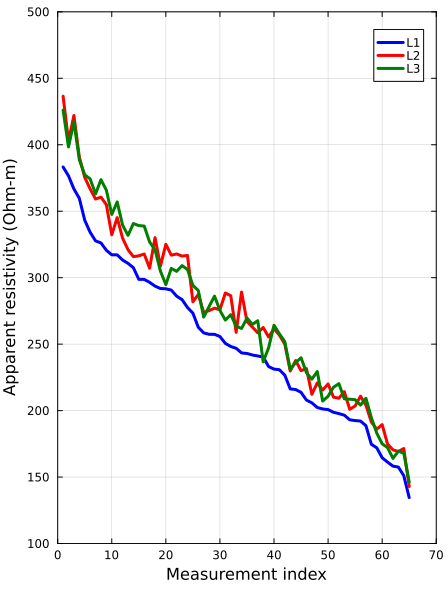

In [2]:
#datas[1,3,1] [line, colum, element]
## Plotagem sem correção do michot
## Plotting without correction from microhot
# Colum 3 is a Apparent resistivity (Ohm-m)
arquivo1= "dados/L1_puraXYZ.dat"
arquivo2= "dados/L2_puraXYZ.dat"
arquivo3= "dados/L3_puraXYZ.dat"
 dados1= readdlm(arquivo1)
  coluna1= dados1[:, 1]
  coluna2= dados1[:, 2]
  coluna3= dados1[:, 3]
 dados2= readdlm(arquivo2)
  coluna1_1= dados2[:, 1]
  coluna2_1= dados2[:, 2]
  coluna3_1= dados2[:, 3]
dados3= readdlm(arquivo3)
  coluna1_2= dados3[:, 1]
  coluna2_2= dados3[:, 2]
  coluna3_2= dados3[:, 3]

StringErro= Float64[2,2,1,2,0,3,0,4,3,5,2,2,2,2,1,5,3,1,2,2,2,0,0,1,1,1,9,4,3,1,0,1,1,3,3,2,3,2,0,2,0,0,0,2,2,2,2,0,2,1,6,1,1,0,2,1,4,1,2,5,2,5,0,1,3]
StringErro3= Float64[7,4,5,5,6,6,11,7,15,7,4,2,4,3,6,2,6,10,1,5,3,4,5,4,5,2,6,4,5,2,1,2,5,2,2,5,6,2,3,4,4,2,4,7,1,3,2,3,3,2,2,3,4,4,5,3,0,3,0,3,3,4,1,0,2]
StringErro2= Float64[2,2,1,2,0,3,0,4,3,5,2,2,2,2,1,5,3,1,2,2,2,0,0,1,1,1,9,4,3,1,0,1,1,3,3,2,3,2,0,2,0,0,0,2,2,2,2,0,2,1,6,1,1,0,2,1,4,1,2,5,2,5,0,1,3]

desvio1= ((StringErro .* coluna3) ./ 100)
desvio2= ((StringErro2.* coluna3_1) ./100)
desvio3= ((StringErro3 .* coluna3_2) ./100)

indices = collect(1:length(coluna3))
perm = sortperm(coluna3, rev=true)

coluna3_1_sinc= coluna3_1[perm]#Dados do arquivo 2 ordenados
coluna3_2_sinc= coluna3_2[perm]#Dados do arquivo 3 ordenados

coluna3_ord= coluna3[perm]
StringErro_sinc= StringErro[perm]
desvio_sinc1= desvio1[perm]
StringErro2_sinc= StringErro2[perm]
desvio_sinc2= desvio2[perm]
StringErro3_sinc= StringErro3[perm]
desvio_sinc3= desvio3[perm]

p1=plot(coluna3_ord , label="" ,
xaxis=((0,70), 0:10:70), yaxis=((100,500), 100:50:500), fmt= :png, linestyle=:solid,grid=true,framestyle=:box,
linewidth = 2, size=(450,600))
plot!(coluna3_ord,lc= :blue, lw= 3, label= "L1")

plot!(coluna3_1_sinc ,  label= "" , mc=:black, msc=:gray,
xaxis=((0,70), 0:10:70), linestyle=:solid,
linewidth = 2)
plot!(coluna3_1_sinc, lc=:red, lw=3, label="L2")

plot!(coluna3_2_sinc ,  label= "",mc=:black, msc=:gray, linestyle=:solid,
linewidth = 2)
plot!(coluna3_2_sinc, lc=:green, lw=3, label="L3" )

xlabel!("Measurement index")
ylabel!("Apparent resistivity (Ohm-m)")

# Correção de temperatura / Temperature correction

In [17]:
# 0.949 it is the value calculated via the Michot correction equation for section L2
# 0.949 é o valor calculado via a equação de Michot de correção, para a seção L2
# 0.9298 it is the value calculated via the Michot correction equation for section L3
# 0.9298 é o valor calculado via a equação de Michot de correção, para a seção L3
coluna3_1c=  coluna3_1 .* 0.949
coluna3_2c= coluna3_2 .* 0.9298

StringErro= Float64[2, 2, 1, 2, 0, 3, 0, 4, 3, 5,2, 2, 2, 2, 1, 5, 3, 1, 2, 2, 2, 0, 0, 1, 1, 1, 9, 4, 3, 1, 0, 1, 1, 3, 3, 2, 3, 2, 0, 2, 0, 0, 0, 2, 2, 2, 2, 0, 2, 1, 6, 1, 1, 0, 2, 1, 4, 1, 2, 5, 2, 5, 0, 1, 3]
StringErro3= Float64[7,4,5,5,6,6,11,7,15,7,4,2,4,3,6,2,6,10,1,5,3,4,5,4,5,2,6,4,5,2,1,2,5,2,2,5,6,2,3,4,4,2,4,7,1,3,2,3,3,2,2,3,4,4,5,3,0,3,0,3,3,4,1,0,2]
StringErro2= Float64[2,2,1,2,0,3,0,4,3,5,2,2,2,2,1,5,3,1,2,2,2,0,0,1,1,1,9,4,3,1,0,1,1,3,3,2,3,2,0,2,0,0,0,2,2,2,2,0,2,1,6,1,1,0,2,1,4,1,2,5,2,5,0,1,3]
desvio1= ((StringErro .* coluna3) ./ 100)
desvio2_= ((StringErro2.* coluna3_1c) ./100)
desvio3_= ((StringErro3 .* coluna3_2c) ./100)

indices = collect(1:length(coluna3))
perm = sortperm(coluna3, rev=true)

coluna3_1_csinc= coluna3_1c[perm]
coluna3_2_csinc= coluna3_2c[perm]

coluna3_ord= coluna3[perm]
#StringErro_sinc= StringErro[perm]
desvio_sinc1= desvio1[perm]
#StringErro2_sinc= StringErro2[perm]
desvio_sinc2= desvio2[perm]
#StringErro3_sinc= StringErro3[perm]
desvio_sinc3= desvio3[perm]
tamanho= length(desvio_sinc3)
println("tamanho: $tamanho")
#savefig("figura8tc")

tamanho: 65


##### Cálculo dos números de pontos recoberto pelos devios.

In [25]:
# Soma dos desvios da L1 e L3, para depois verificar se os dados da L1 estão entre o desvio padrão
# Sum of the deviations for L1 and L3, to subsequently check whether the L1 data fall within the standard deviation
desvios_somados = desvio_sinc1 .+ desvio_sinc3
zonarefe_subt= abs.(coluna3_ord .- coluna3_2_csinc)# valor absoluto da subtração de L1-L3
pontos= 0
# Coluna3_orde é a Seção L1 ordenada em forma descresente.
for i in 1:length(coluna3_ord)
  if zonarefe_subt[i] < desvios_somados[i]
    pontos+= 1
  end
end
pontos_por= (100*pontos)/ length(coluna3_ord)
pontos_por= round(pontos_por, digits=2)
println("O números de pontos recobertos é de $pontos, ou seja $pontos_por% do total.")

O números de pontos recobertos é de 53, ou seja 81.54% do total.


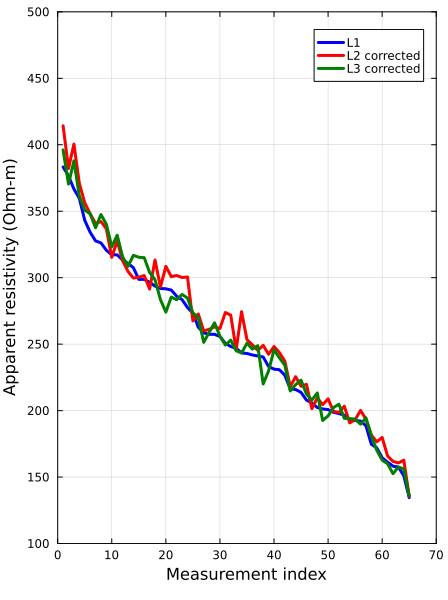

In [18]:
p2=plot(coluna3_ord , label="" ,
xaxis=((0,70), 0:10:70), yaxis=((100,500), 100:50:500), fmt= :png, linestyle=:solid,grid=true,framestyle=:box,
linewidth = 2, size=(450,600))
plot!(coluna3_ord,lc= :blue, lw= 3, label= "L1")

plot!(coluna3_1_csinc ,  label= "",
xaxis=((0,70), 0:10:70), linestyle=:solid,
linewidth = 2)
plot!(coluna3_1_csinc, lc=:red, lw=3, label="L2 corrected")

plot!(coluna3_2_csinc, label= "", mc=:black, msc=:gray,
xaxis=((0,70), 0:10:70), linestyle=:solid,
linewidth = 2)
plot!(coluna3_2_csinc, lc=:green, lw=3, label="L3 corrected")
xlabel!("Measurement index")
ylabel!("Apparent resistivity (Ohm-m)")

#savefig("figura8ct")

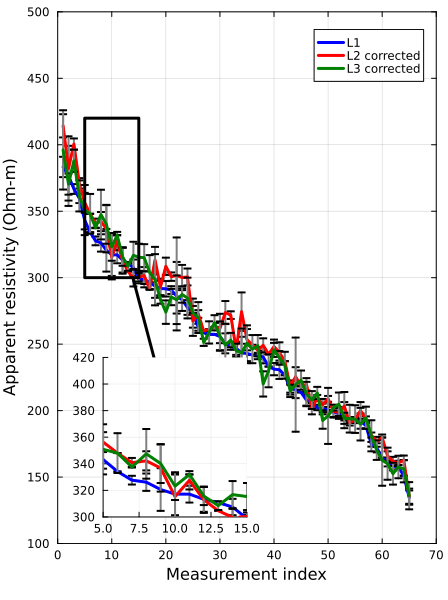

In [19]:
p3=plot(coluna3_ord , label="" ,yerr=desvio_sinc1,mc=:black, msc=:gray,
xaxis=((0,70), 0:10:70), yaxis=((100,500), 100:50:500), fmt= :png, linestyle=:solid,grid=true,framestyle=:box,
linewidth = 2, size=(450,600))
plot!(coluna3_ord,lc= :blue, lw= 3, label= "L1")

plot!(coluna3_1_csinc, yerr=desvio_sinc2,  label= "",mc=:black, msc=:gray,
xaxis=((0,70), 0:10:70), linestyle=:solid,
linewidth = 2)
plot!(coluna3_1_csinc, lc=:red, lw=3, label="L2 corrected")

plot!(coluna3_2_csinc,yerr= desvio_sinc3, label= "", mc=:black, msc=:gray,
xaxis=((0,70), 0:10:70), linestyle=:solid,
linewidth = 2)
plot!(coluna3_2_csinc, lc=:green, lw=3, label="L3 corrected")
xlabel!("Measurement index")
ylabel!("Apparent resistivity (Ohm-m)")
lens!([5, 15], [300,420], inset = (1, bbox(0.12, 0.65, 0.38, 0.3)),
linewidth= 3, linecolors= :black)

# Fazenda Daterra em Franca/ Farm Daterra in Franca

In [3]:
cubo=readdlm("dados/S1.dat")
cubo1=readdlm("dados/S17.dat")
cubo2= readdlm("dados/S34.dat")
  erro1= cubo[:, 6]#Coluna do erro experimental/ Colum experimental error
  res1= cubo[:, 8]#Coluna da resistividade aparente / Colum of Apparent resistivity
  erro2= cubo1[:, 6]
  res2= cubo1[:, 8]
  erro3= cubo2[:, 6]
  res3= cubo2[:, 8]

println(length(res1))
println(length(res2))
print(length(res3))

111
111
111

In [4]:
desv1= ((erro1 .* res1) ./ 100)
desv2= ((erro2 .* res2)./100)
desv3= ((erro3 .* res3)./100)

# Ordena a coluna da resistividade de forma descrescente, usando a coluna 2 como referência
rfc = collect(1:length(res1))
ordem = sortperm(res1, rev=true)

# Resistividades e desvios-padrões ordenados
Rho_a1= res1[ordem]
Rho_a2= res2[ordem]
Rho_a3= res3[ordem]
desv1_ordem= desv1[ordem]
desv2_ordem= desv2[ordem]
desv3_ordem= desv3[ordem]
print(1)

1

In [5]:
plot(Rho_a1, label="L1", lw=2, grid=true,framestyle=:box, size=(450,600),
yaxis=((100,1500), 100:250:1500), yerr=desv1_ordem ,mc=:black, msc=:gray)#S1
plot!(Rho_a2, label="L2", lw=2, linestyle= :solid, yerr= desv2_ordem,mc=:black, msc=:gray)#S17
plot!(Rho_a3, label="L3", lw=2, linestyle= :solid, yerr= desv3_ordem,mc=:black, msc=:gray)#s34
xlabel!("Measurement index")
ylabel!("Apparent resistivity (ohm-m)")
savefig("Daterra Farm")

"C:\\Users\\mathe\\jls\\Daterra Farm.png"

In [ ]:
#Para S17, temperatura de referência da S1 é 26.5, temperatura da S17 25.7
Tc= 1 + (0.02*(25.7-26.5))
#Para S34, temperatua de 24.6
Tc1= 1 +( 0.02*(24.6-26.5))

res2_tc= res2 .* Tc
res3_tc= res3 .* Tc1
Rhoa2_tc= res2_tc[ordem]
Rhoa3_tc= res3_tc[ordem]

Como A S34 já está "colada" com a S1, a correção pela temperatura a rebaixa em relação a S1

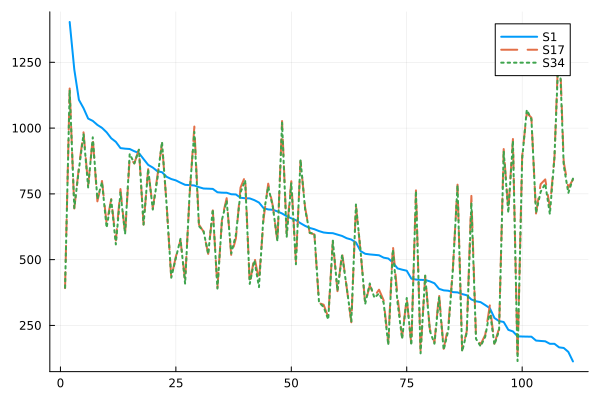

In [ ]:
plot(Rho_a1, label="S1", lw=2)
plot!(Rhoa2_tc ,label="S17", lw=2, linestyle= :dash)
plot!(Rhoa3_tc, label="S34", lw=2, linestyle= :dot)